# Lab 5 - EDA
Zbiór: Red Wine Quality (Kaggle): https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Krok 2 - wczytanie danych

In [2]:
df = pd.read_csv('winequality-red.csv')

In [3]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Krok 3 - analiza EDA

In [4]:
df.shape

(1599, 12)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [7]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

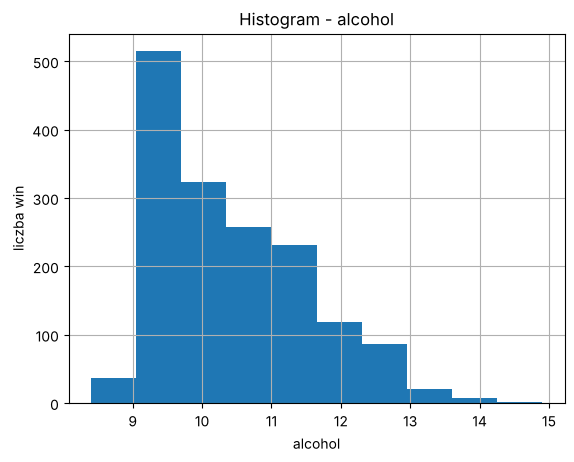

In [8]:
df['alcohol'].hist()
plt.title('Histogram - alcohol')
plt.xlabel('alcohol')
plt.ylabel('liczba win')
plt.show()

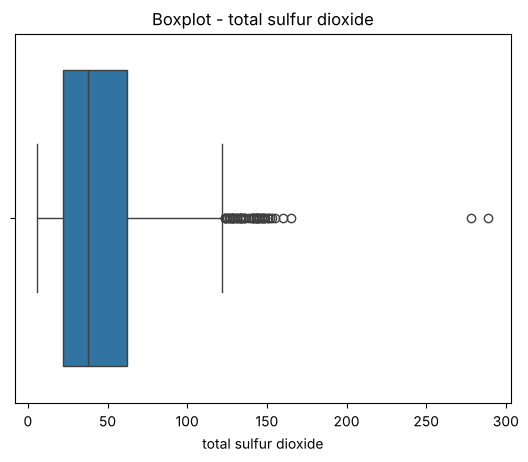

In [9]:
sns.boxplot(x=df['total sulfur dioxide'])
plt.title('Boxplot - total sulfur dioxide')
plt.show()

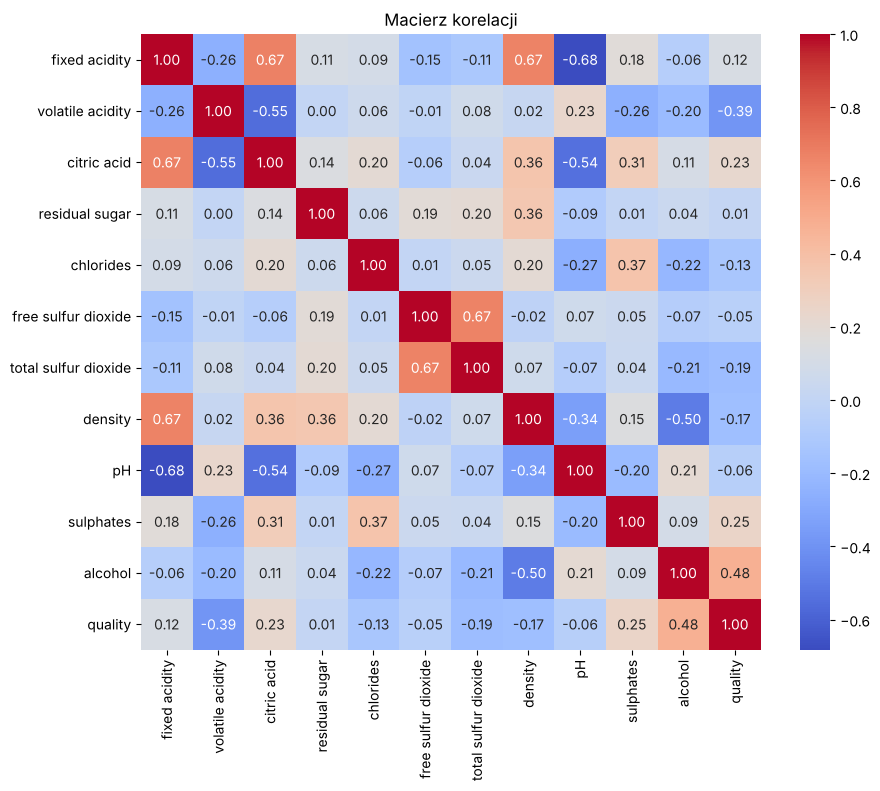

In [10]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Macierz korelacji')
plt.show()

## Zadanie 1 - druga zmienna (residual sugar)

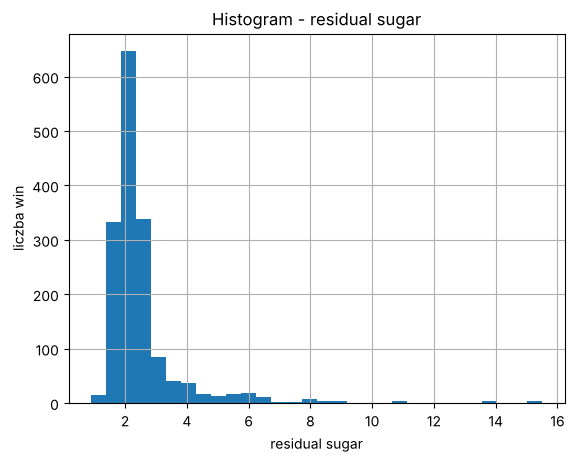

In [11]:
df['residual sugar'].hist(bins=30)
plt.title('Histogram - residual sugar')
plt.xlabel('residual sugar')
plt.ylabel('liczba win')
plt.show()

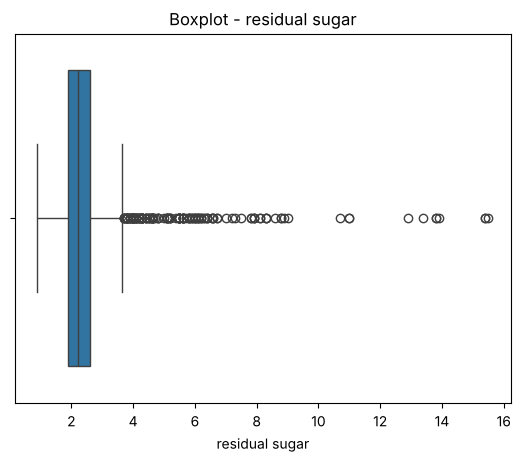

In [12]:
sns.boxplot(x=df['residual sugar'])
plt.title('Boxplot - residual sugar')
plt.show()

In [13]:
q1 = df['residual sugar'].quantile(0.25)
q3 = df['residual sugar'].quantile(0.75)
iqr = q3 - q1
odstajace = df[(df['residual sugar'] < q1 - 1.5 * iqr) | (df['residual sugar'] > q3 + 1.5 * iqr)]
print('Liczba wartości odstających:', len(odstajace))
print('Średnia:', round(df['residual sugar'].mean(), 2), 'Mediana:', df['residual sugar'].median())

Liczba wartości odstających: 155
Średnia: 2.54 Mediana: 2.2


Wniosek: rozkład residual sugar jest mocno prawostronnie skośny, większość win ma 1,5-3 g/l cukru, a boxplot pokazuje około 155 wartości odstających (pojedyncze wina mają nawet 15,5).

## Zadanie 2 - braki danych

In [14]:
(df.isnull().mean() * 100).round(1)

fixed acidity           0.0
volatile acidity        0.0
citric acid             0.0
residual sugar          0.0
chlorides               0.0
free sulfur dioxide     0.0
total sulfur dioxide    0.0
density                 0.0
pH                      0.0
sulphates               0.0
alcohol                 0.0
quality                 0.0
dtype: float64

In [15]:
df.duplicated().sum()

np.int64(240)

Wniosek: w żadnej kolumnie nie ma braków (0% wszędzie), więc nie trzeba nic usuwać ani uzupełniać. Zbiór jest kompletny, pewnie dlatego, że to pomiary laboratoryjne i był już wcześniej przygotowany przez autorów. Przy okazji wyszło, że 240 wierszy to duplikaty, co trzeba będzie wziąć pod uwagę przy przygotowaniu danych.

## Zadanie 3 - zależność dwóch zmiennych

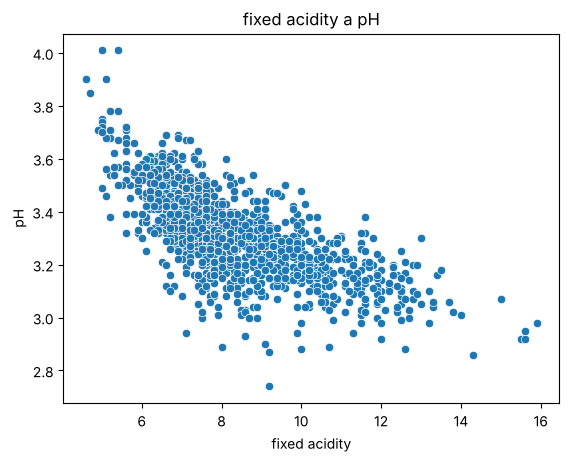

In [16]:
sns.scatterplot(x='fixed acidity', y='pH', data=df)
plt.title('fixed acidity a pH')
plt.show()

In [17]:
round(df['fixed acidity'].corr(df['pH']), 2)

np.float64(-0.68)

Wniosek: najsilniejsza korelacja na heatmapie to fixed acidity i pH (-0,68). Zależność jest ujemna i dość silna: im więcej kwasów, tym niższe pH. Sama korelacja nie dowodzi jednak, że jedna zmienna powoduje drugą, bo pokazuje tylko, że zmienne zmieniają się razem. Przyczyną może być trzecia zmienna albo przypadek. Tutaj akurat wiemy z chemii, że kwasy obniżają pH, ale tego nie wiemy z samej korelacji.